### 1. Importacion de bibliotecas y carga de datos

In [1]:
#Importacion de bibliotecas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#Asigo el csv a una variable, leo el archivo para crear el dataframe, y realizo una copia para realizar las modificaciones, preservando el dataframe original.

archivo_restaurantes = 'base_datos_restaurantes_USA_v2.csv'
df_restaurantes = pd.read_csv(archivo_restaurantes)
df_restaurantes_limpio = df_restaurantes.copy()
                              

### 2. Exploración inicial y detección de inconsistencias

Utilizamos `.info()`, `.describe()`, `.dtypes` y `.head()` para explorar la estructura del dataset. Mediante `.unique()`, `.isna()` y `.duplicated()`, analizamos los valores de las variables, los datos faltantes y los posibles duplicados. También identificamos valores potencialmente inconsistentes, como edades fuera de rango y gastos negativos.

In [3]:
df_restaurantes.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

In [4]:
#Verificacion de valores para diferentes columnas para identificar valores fuera de lo comun.

df_restaurantes.describe()

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29899.000000,30000.000000,29855.000000,30000.000000
mean,5.504765e+09,49.665006,3.896133,32.603452,5389.755867
std,2.602799e+09,23.839550,2.741532,26.402601,4538.491728
min,1.000153e+09,-5.000000,-3.000000,0.000000,800.000000
25%,3.243617e+09,33.000000,2.000000,13.290000,1860.000000
50%,5.515865e+09,49.000000,4.000000,25.510000,3402.000000
75%,7.754426e+09,65.000000,5.000000,44.400000,7761.000000
max,9.999627e+09,300.000000,10.000000,149.970000,17999.000000


In [5]:
df_restaurantes.dtypes

id_persona                     int64
nombre                           str
apellido                         str
edad                         float64
genero                           str
ciudad_residencia                str
estrato_socioeconomico           str
frecuencia_visita              int64
promedio_gasto_comida        float64
ocio                             str
consume_licor                    str
preferencias_alimenticias        str
membresia_premium                str
telefono_contacto                str
correo_electronico               str
tipo_de_pago_mas_usado           str
ingresos_mensuales             int64
dtype: object

In [6]:
#Comprobamos la estructura para entender mejor el DataFrame

df_restaurantes.head()

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


In [7]:
#Verificacion de Valores Unicos

print(df_restaurantes['ciudad_residencia'].unique())
print(df_restaurantes['estrato_socioeconomico'].unique())
print(df_restaurantes['membresia_premium'].unique())
print(df_restaurantes['tipo_de_pago_mas_usado'].unique())
print(df_restaurantes['preferencias_alimenticias'].unique())
print(df_restaurantes['genero'].unique())

<StringArray>
[    'Miami',    'Denver',    'Boston', 'San Diego',    'Dallas',       'NYC',
   'Seattle',   'Chicago',   'Houston',   'Phoenix']
Length: 10, dtype: str
<StringArray>
['Alto', 'Medio', 'Bajo', 'Muy Alto']
Length: 4, dtype: str
<StringArray>
['Sí', 'No']
Length: 2, dtype: str
<StringArray>
['Efectivo', 'Tarjeta', 'App', 'Criptomoneda']
Length: 4, dtype: str
<StringArray>
['Vegetariano', 'Mariscos', 'Carnes', 'Vegano', 'Pescado', nan, 'Otro']
Length: 7, dtype: str
<StringArray>
['Masculino', 'Femenino']
Length: 2, dtype: str


In [8]:
#Verificacion de porcentaje de Nulos de todo el dataset

porcentaje_nulos = (df_restaurantes.isna().mean() *100).round(2)
porcentaje_nulos

id_persona                    0.00
nombre                        0.00
apellido                      0.00
edad                          0.34
genero                        0.00
ciudad_residencia             0.00
estrato_socioeconomico        0.00
frecuencia_visita             0.00
promedio_gasto_comida         0.48
ocio                          0.00
consume_licor                 0.00
preferencias_alimenticias     4.68
membresia_premium             0.00
telefono_contacto            50.55
correo_electronico           50.24
tipo_de_pago_mas_usado        0.00
ingresos_mensuales            0.00
dtype: float64

Valores nulos encontrados:
Edad = 0.34%,
Promedio Gasto = 0.48%,
Preferencias Alimenticias = 4.68%,
Telefonos = 50.55%,
Correos = 50.24%,

In [9]:
#Busqueda de valores duplicados

df_duplicados = (df_restaurantes.duplicated(subset=['id_persona' , 'nombre']))

cantidad_duplicados = df_duplicados.sum()
print(cantidad_duplicados)

0


### 3. Detección de valores negativos

Se revisan las columnas numéricas para identificar valores negativos potencialmente inconsistentes. Su tratamiento se evalúa según el significado de cada variable y el contexto de los datos.

In [10]:
# Edades negativas

df_restaurantes.loc[df_restaurantes['edad'] < 0, ['nombre' , 'edad']]

,nombre,edad
532,Rebecca,-5.0
960,William,-5.0
1381,Katie,-5.0
1774,Kimberly,-5.0
2302,Brian,-5.0
...,...,...
28524,Krista,-5.0
28748,Nicole,-5.0
29467,Lauren,-5.0
29708,Anthony,-5.0


In [11]:
# Frecuencia de visitas negativa

df_restaurantes.loc[df_restaurantes['frecuencia_visita'] < 0, ['nombre' , 'frecuencia_visita']]


,nombre,frecuencia_visita
36,Raymond,-3
38,Michael,-3
39,Linda,-3
71,Tim,-3
80,Julie,-3
...,...,...
29891,Andrew,-3
29896,Angelica,-3
29904,Alexander,-3
29944,Aaron,-3


In [12]:
# Gastos negativos

df_restaurantes[df_restaurantes['promedio_gasto_comida'] < 0]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


In [13]:
# Ingresos negativos

df_restaurantes[df_restaurantes['ingresos_mensuales'] < 0]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


Valores negativos encontrados en edad = 97 registros y frecuencia de visita = 1547 registros

### 4. Limpieza de Datos

### Limpieza e imputacion de la columna edad

In [14]:
#Creo una mascara para identificar valores fuera de lo comun y las remplazo por valores nulos

edades_anomalas = (df_restaurantes_limpio['edad'] < 0) | (df_restaurantes['edad'] > 110)

#Verifico que son pocas en relacion a la cantidad de registros totales por lo que las remplazo con valores nulos por el momento.

edades_anomalas.sum()

df_restaurantes_limpio.loc[edades_anomalas, 'edad'] =np.nan

In [15]:
#El porcentaje de nulos en edad es muy bajo y puede ser trabajado imputando la edad mediana de todos los registros sin comprometer futuros resultados.

mediana_edad = df_restaurantes_limpio['edad'].median()
df_restaurantes_limpio['edad'] = df_restaurantes_limpio ['edad'].fillna(mediana_edad)


In [16]:
#Verifico que se hayan imputado correctamente

df_restaurantes_limpio[df_restaurantes_limpio['edad'].isna()]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


### Limpieza en frecuencia_visita

In [17]:
# Verifico cuantos registros son anomalos 

(df_restaurantes_limpio['frecuencia_visita'] < 0).sum()



np.int64(1547)

In [18]:
df_restaurantes_limpio.loc [df_restaurantes_limpio['frecuencia_visita'] < 0,
    ['id_persona', 'nombre', 'apellido', 'frecuencia_visita']]

,id_persona,nombre,apellido,frecuencia_visita
36,1712727648,Raymond,Boyer,-3
38,3098578259,Michael,Patterson,-3
39,9760264518,Linda,Stewart,-3
71,9379340450,Tim,English,-3
80,7695630064,Julie,Davis,-3
...,...,...,...,...
29891,8817035453,Andrew,Beck,-3
29896,1871940551,Angelica,Barrett,-3
29904,2889395973,Alexander,Suarez,-3
29944,5463363175,Aaron,Charles,-3


In [19]:
#Veo cuantas veces aparece cada valor y verifico que todos los negativos son -3

df_restaurantes_limpio['frecuencia_visita'].value_counts().sort_index()

frecuencia_visita
-3     1547
 0     1463
 1     1459
 2     3659
 3     3697
 4     5042
 5     5932
 6     3746
 7      878
 8      862
 9      839
 10     876
Name: count, dtype: int64

Identifico 1.547 registros con un valor de 
-3, lo que requiere investigar su significado antes de decidir cómo tratarlos.


In [20]:
#Los visitas = 0 poseen gastos en comida?

df_restaurantes_limpio.loc[(df_restaurantes_limpio['frecuencia_visita'] == 0) & (df_restaurantes_limpio['promedio_gasto_comida'] > 0 ), ['frecuencia_visita' , 'promedio_gasto_comida']]

,frecuencia_visita,promedio_gasto_comida


In [21]:
#Los visitas = -3 poseen gastos en comida?

df_restaurantes_limpio.loc[(df_restaurantes_limpio['frecuencia_visita'] == -3) & (df_restaurantes_limpio['promedio_gasto_comida'] > 0 ), ['frecuencia_visita' , 'promedio_gasto_comida']]

,frecuencia_visita,promedio_gasto_comida
36,-3,10.08
38,-3,83.97
39,-3,40.06
71,-3,37.66
80,-3,45.97
...,...,...
29891,-3,18.89
29896,-3,43.69
29904,-3,28.35
29944,-3,11.29


Al verificar que los valores negativos tienen gastos, no puedo tratarlos como 0 por los que los interpreto como desconocidos y los transformo en nulos

In [22]:
df_restaurantes_limpio.loc[df_restaurantes_limpio['frecuencia_visita'] == -3, 'frecuencia_visita'] = np.nan

In [23]:
#Compruebo la media y la mediana

print(df_restaurantes_limpio['frecuencia_visita'].mean())
print(df_restaurantes_limpio['frecuencia_visita'].median())

4.2710786208835625
4.0


Durante el análisis del dataframe, observo además una tendencia entre el nivel socioeconómico y la frecuencia de visitas, los niveles socioeconómicos más altos parecen presentar una mayor frecuencia de visitas.
A partir de esta observación, decido imputar los valores faltantes utilizando la mediana de frecuencia_visita correspondiente a cada nivel socioeconómico. De esta manera, cada registro recibe un valor basado en el comportamiento del grupo al que pertenece, en lugar de utilizar una única medida para todo el dataset.

In [24]:
#Compruebo que la frecuencia de visitas aumenta segun el Nivel Socioeconomico

visita_mediana_estrato = df_restaurantes_limpio.groupby('estrato_socioeconomico')['frecuencia_visita'].median()
print(visita_mediana_estrato)

estrato_socioeconomico
Alto        5.0
Bajo        2.0
Medio       3.0
Muy Alto    7.0
Name: frecuencia_visita, dtype: float64


In [25]:
#A los valores nulos, les asigno la mediana segun el nivel socioeconomico correspondiente

visitas_nulas = df_restaurantes_limpio['frecuencia_visita'].isna()

df_restaurantes_limpio.loc[visitas_nulas, 'frecuencia_visita'] = (df_restaurantes_limpio.loc[visitas_nulas, 'estrato_socioeconomico'] .map(visita_mediana_estrato))

In [26]:
#Compruebo si siguen existiendo valores nulos

df_restaurantes_limpio['frecuencia_visita'].isna().sum()

np.int64(0)

### Limpieza columna 'promedio_gasto_comida'

In [27]:
#Cuento valores nulos en la columna

df_restaurantes_limpio['promedio_gasto_comida'].isna().sum()

np.int64(145)

In [28]:
#Verifico si hay valores negativos

df_restaurantes_limpio.loc[df_restaurantes_limpio['promedio_gasto_comida'] < 0]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


Al igual que con la fecuencia de visitas, el promedio de gasto aumenta segun nivel socio economico

In [29]:
gasto_mediana_estrato = df_restaurantes_limpio.groupby('estrato_socioeconomico')['promedio_gasto_comida'].median()
print(gasto_mediana_estrato)

estrato_socioeconomico
Alto        37.43
Bajo         9.59
Medio       23.48
Muy Alto    63.38
Name: promedio_gasto_comida, dtype: float64


In [30]:
#A los valores nulos, les asigno la mediana segun el nivel socioeconomico correspondiente

promedio_gastos_nulos = df_restaurantes_limpio['promedio_gasto_comida'].isna()

df_restaurantes_limpio.loc[promedio_gastos_nulos, 'promedio_gasto_comida'] = (df_restaurantes_limpio.loc[promedio_gastos_nulos, 'estrato_socioeconomico'] .map(gasto_mediana_estrato))

### Limpieza columna 'preferencias_alimenticias'

In [31]:
df_restaurantes_limpio['preferencias_alimenticias'].isna().mean()*100

np.float64(4.676666666666667)

In [32]:
#Compruebo que solo existen valores validos y cuento nulos

df_restaurantes_limpio['preferencias_alimenticias'].value_counts(dropna=False)

preferencias_alimenticias
Carnes         7916
Vegetariano    6580
Mariscos       5212
Vegano         3267
Pescado        2983
Otro           2639
NaN            1403
Name: count, dtype: int64

In [33]:
#Asigo a los valores faltantes con 'Desconocido' para no asumir preferencias erroneas

df_restaurantes_limpio['preferencias_alimenticias'] = (df_restaurantes_limpio['preferencias_alimenticias'].fillna('Desconocido'))

In [34]:
df_restaurantes_limpio['preferencias_alimenticias'].isna().sum()


np.int64(0)

### Tratamiento correo_electronico

In [35]:
df_restaurantes_limpio['correo_electronico'].isna().sum()

np.int64(15072)

In [36]:
(df_restaurantes_limpio['correo_electronico'].isna().mean()*100).round(2)

np.float64(50.24)

Los valores nulos de correo_electronico eran alrededor del 50%, por lo que hay que tratarlos con cuidado ya que una mala imputación puede alterar el resultado de nuestros análisis profundamente. Primero verificamos cuantos registros existen, el porcentaje de nulos y si hay duplicados.

In [37]:
#Verifico si hay valores que se repiten y cuento nulos nuevamente

df_restaurantes_limpio['correo_electronico'].value_counts(dropna=False)


correo_electronico
NaN                            15072
pjohnson@example.org               4
wbrown@example.net                 4
millerdavid@example.org            3
jason75@example.net                3
                               ...  
georgesellers@example.net          1
pmorris@example.org                1
michaelrobinson@example.net        1
garciagregory@example.net          1
jimmy77@example.org                1
Name: count, Length: 14475, dtype: int64

In [38]:
#Creo las mascaras para verificar correos validos y duplicados

correos_validos = df_restaurantes_limpio['correo_electronico'].dropna()

correos_duplicados = correos_validos[correos_validos.duplicated(keep=False)]


In [39]:
print("Correos distintos duplicados:", correos_duplicados.nunique())
print("Registros con correos duplicados:", len(correos_duplicados))

Correos distintos duplicados: 417
Registros con correos duplicados: 871


In [40]:
#Compruebo que los valores duplicados corresponden a diferentes id_persona, nombre y apellido.

df_restaurantes_limpio.loc[df_restaurantes_limpio['correo_electronico'].isin(correos_duplicados),
    ['id_persona', 'nombre', 'apellido', 'correo_electronico']].sort_values('correo_electronico')

,id_persona,nombre,apellido,correo_electronico
25630,4584144878,John,Conley,alicia33@example.net
7330,4642197907,Katherine,Berry,alicia33@example.net
12254,7137748626,Mason,Miller,alopez@example.com
22212,5738967614,Cameron,Orr,alopez@example.com
7114,5455242170,Tasha,Taylor,amanda50@example.com
...,...,...,...,...
6180,1987243526,Michael,Davenport,zthompson@example.org
12232,2036388089,Kathryn,Ortiz,zvasquez@example.org
5161,6884723824,Nicole,Thompson,zvasquez@example.org
11594,8117478955,Patricia,Calhoun,zwilliams@example.org


En este caso se identificaron 417 direcciones de correo electrónico repetidas, presentes en un total de 871 registros. Los registros presentan identificadores de persona únicos. Por lo que valores repetidos en email, no significan registros duplicados

In [41]:
#Chequeamos si existen correos que no cumplan con el patron correspondiente a un formato basico tipo usuario@dominio.com

correos_invalidos = correos_validos[
    ~correos_validos.str.contains(
        r'^[^@\s]+@[^@\s]+\.[^@\s]+$',
        regex=True
    )
]

print(correos_invalidos)

Series([], Name: correo_electronico, dtype: str)


In [42]:
# Reemplazamos los valores nulos de correo_electronico para evitar errores mas adelante

df_restaurantes_limpio['correo_electronico'] = (
    df_restaurantes_limpio['correo_electronico'].fillna('Sin correo'))

In [43]:
df_restaurantes_limpio['correo_electronico'].isna().sum()

np.int64(0)

### Limpieza de telefono_contacto

In [44]:
nulos = df_restaurantes_limpio.isna().sum()
print(nulos)

id_persona                       0
nombre                           0
apellido                         0
edad                             0
genero                           0
ciudad_residencia                0
estrato_socioeconomico           0
frecuencia_visita                0
promedio_gasto_comida            0
ocio                             0
consume_licor                    0
preferencias_alimenticias        0
membresia_premium                0
telefono_contacto            15166
correo_electronico               0
tipo_de_pago_mas_usado           0
ingresos_mensuales               0
dtype: int64


In [45]:
#Comprobamos cuantas veces aparece cada registro incluyendo los nulos y vemos que no hay valores duplicados

df_restaurantes_limpio['telefono_contacto'].value_counts(dropna=False).head(10)

telefono_contacto
NaN                      15166
(830)220-1926                1
881-476-1426                 1
243.248.8919                 1
976.606.6259x578             1
001-327-542-1940x4789        1
563-346-4749x6591            1
+1-881-859-5881x2368         1
332-647-0730                 1
(394)853-1965                1
Name: count, dtype: int64

In [46]:
#Contamos cuantos valores son validos y cuantos nulos

telefonos_validos = df_restaurantes_limpio['telefono_contacto'].dropna()

print("Teléfonos informados:", len(telefonos_validos))
print("Teléfonos nulos:", df_restaurantes_limpio['telefono_contacto'].isna().sum())

Teléfonos informados: 14834
Teléfonos nulos: 15166


In [47]:
# Aplicando el mismo razonamiento que en el caso de los correos reemplazo los valores nulos de telefono_contacto para evitar errores mas adelante

df_restaurantes_limpio['telefono_contacto'] = (
    df_restaurantes_limpio['telefono_contacto'].fillna('Sin Telefono')
)

In [48]:
print("Teléfonos nulos:", df_restaurantes_limpio['telefono_contacto'].isna().sum())

Teléfonos nulos: 0


In [49]:
#Verificamos que no queden Nulos en todo el DataFrame

nulos = df_restaurantes_limpio.isna().sum()
print(nulos)

id_persona                   0
nombre                       0
apellido                     0
edad                         0
genero                       0
ciudad_residencia            0
estrato_socioeconomico       0
frecuencia_visita            0
promedio_gasto_comida        0
ocio                         0
consume_licor                0
preferencias_alimenticias    0
membresia_premium            0
telefono_contacto            0
correo_electronico           0
tipo_de_pago_mas_usado       0
ingresos_mensuales           0
dtype: int64


### 5. Filtrado por ciudad de residencia
Una vez terminado la limpieza de datos, me decido trabajar con la ciudad de Dallas

In [50]:
df_restaurantes_limpio['ciudad_residencia'].unique()


<StringArray>
[    'Miami',    'Denver',    'Boston', 'San Diego',    'Dallas',       'NYC',
   'Seattle',   'Chicago',   'Houston',   'Phoenix']
Length: 10, dtype: str

In [51]:
df_dallas = df_restaurantes_limpio[df_restaurantes_limpio['ciudad_residencia'] == 'Dallas'].copy()

In [52]:
print(f'La cantidad de registros en Dallas: {len(df_dallas)}')
df_dallas.head()

La cantidad de registros en Dallas: 2602


,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
5,1291749568,Donna,Davis,26.0,Femenino,Dallas,Alto,6.0,52.47,No,Sí,Carnes,Sí,976.606.6259x578,daniel28@example.com,Efectivo,8545
54,1946694104,Thomas,Patel,23.0,Masculino,Dallas,Bajo,1.0,8.19,No,Sí,Pescado,No,Sin Telefono,Sin correo,Tarjeta,1198
65,6593496559,Charlene,Gordon,41.0,Femenino,Dallas,Medio,2.0,12.29,No,No,Vegano,Sí,Sin Telefono,maryoneill@example.net,Tarjeta,3439
91,6195191209,Robert,Wilson,77.0,Masculino,Dallas,Bajo,2.0,10.65,Sí,Sí,Carnes,No,Sin Telefono,scottsmith@example.com,App,1188
96,4218845963,Shawn,Good,33.0,Masculino,Dallas,Alto,5.0,5.11,No,No,Carnes,No,Sin Telefono,cameronkevin@example.org,Tarjeta,5056


### Distribución de variables categóricas

A partir de los registros correspondientes a Dallas, se generan tablas de frecuencia y porcentajes para analizar la distribución de variables como género, edad, preferencias alimenticias, consumo de licor, membresía premium, frecuencia de visita, medios de pago, estrato socioeconómico y ocio. Los resultados permiten identificar las categorías predominantes y describir las características de los clientes de la ciudad.

In [53]:
columnas_categoricas = [
    'genero',
    'edad',
    'preferencias_alimenticias',
    'consume_licor',
    'membresia_premium',
    'frecuencia_visita',
    'tipo_de_pago_mas_usado',
    'estrato_socioeconomico',
    'ocio'
]

for columna in columnas_categoricas:
    print(f"\n--- Distribución de {columna} ---")

    tabla = pd.DataFrame({
        'Frecuencia': df_dallas[columna].value_counts(dropna=False),
        'Porcentaje (%)': (df_dallas[columna].value_counts(normalize=True, dropna=False) * 100).round(2)})
    display(tabla)


--- Distribución de genero ---


,Frecuencia,Porcentaje (%)
genero,,
Masculino,1350,51.88
Femenino,1252,48.12



--- Distribución de edad ---


,Frecuencia,Porcentaje (%)
edad,,
49.0,80,3.07
56.0,52,2.00
68.0,52,2.00
69.0,51,1.96
27.0,50,1.92
...,...,...
61.0,31,1.19
34.0,30,1.15
59.0,30,1.15



--- Distribución de preferencias_alimenticias ---


...

,Frecuencia,Porcentaje (%)
tipo_de_pago_mas_usado,,
Efectivo,1015,39.01
Tarjeta,869,33.40
App,671,25.79
Criptomoneda,47,1.81



--- Distribución de estrato_socioeconomico ---


,Frecuencia,Porcentaje (%)
estrato_socioeconomico,,
Medio,863,33.17
Alto,737,28.32
Bajo,625,24.02
Muy Alto,377,14.49



--- Distribución de ocio ---


,Frecuencia,Porcentaje (%)
ocio,,
No,1308,50.27
Sí,1294,49.73


### Creo tablas que muestran el porcentaje de preferencias alimenticias para cada nivel socioeconomico

In [54]:
niveles = ['Bajo', 'Medio', 'Alto', 'Muy Alto']

# Genero una tabla de preferencias para cada nivel socioeconómico.
for nivel in niveles:
    datos = df_dallas[
        df_dallas['estrato_socioeconomico'] == nivel
    ]

    # Calculo el porcentaje de cada preferencia dentro del nivel.
    porcentajes = (
        datos['preferencias_alimenticias']
        .value_counts(normalize=True) * 100
    ).round(2)

    # Ordeno los porcentajes de mayor a menor y creo la tabla.
    tabla = porcentajes.sort_values(ascending=False).reset_index()
    tabla.columns = ['Preferencia alimenticia', 'Porcentaje (%)']

    print(f'\nNivel socioeconómico: {nivel}')
    display(tabla)


Nivel socioeconómico: Bajo


,Preferencia alimenticia,Porcentaje (%)
0,Carnes,31.68
1,Vegetariano,19.04
2,Mariscos,14.40
3,Pescado,10.40
4,Vegano,9.76
5,Otro,9.60
6,Desconocido,5.12



Nivel socioeconómico: Medio


,Preferencia alimenticia,Porcentaje (%)
0,Carnes,32.91
1,Vegetariano,19.93
2,Mariscos,13.33
3,Vegano,11.36
4,Otro,9.50
5,Pescado,7.65
6,Desconocido,5.33



Nivel socioeconómico: Alto


,Preferencia alimenticia,Porcentaje (%)
0,Carnes,31.34
1,Vegetariano,22.25
2,Mariscos,15.33
3,Pescado,10.18
4,Otro,9.63
5,Vegano,7.60
6,Desconocido,3.66



Nivel socioeconómico: Muy Alto


,Preferencia alimenticia,Porcentaje (%)
0,Carnes,28.91
1,Vegetariano,22.28
2,Mariscos,12.73
3,Vegano,11.41
4,Otro,9.55
5,Pescado,8.75
6,Desconocido,6.37


In [55]:
df_restaurantes_limpio

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6.0,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,Sin correo,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2.0,44.92,Sí,Sí,Mariscos,No,881-476-1426,Sin correo,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2.0,9.24,Sí,Sí,Vegetariano,No,Sin Telefono,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5.0,30.74,Sí,Sí,Carnes,Sí,Sin Telefono,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0.0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,4862097674,Robert,Cortez,20.0,Masculino,Houston,Alto,5.0,30.82,Sí,Sí,Vegano,Sí,Sin Telefono,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78.0,Masculino,Denver,Alto,5.0,45.04,No,No,Mariscos,No,Sin Telefono,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77.0,Femenino,San Diego,Muy Alto,7.0,93.55,No,Sí,Mariscos,Sí,Sin Telefono,Sin correo,Efectivo,12639
29998,8853079811,Tamara,Griffin,77.0,Femenino,Chicago,Bajo,1.0,6.18,Sí,No,Otro,No,(243)658-6543x11668,Sin correo,Tarjeta,1057


## Graficos

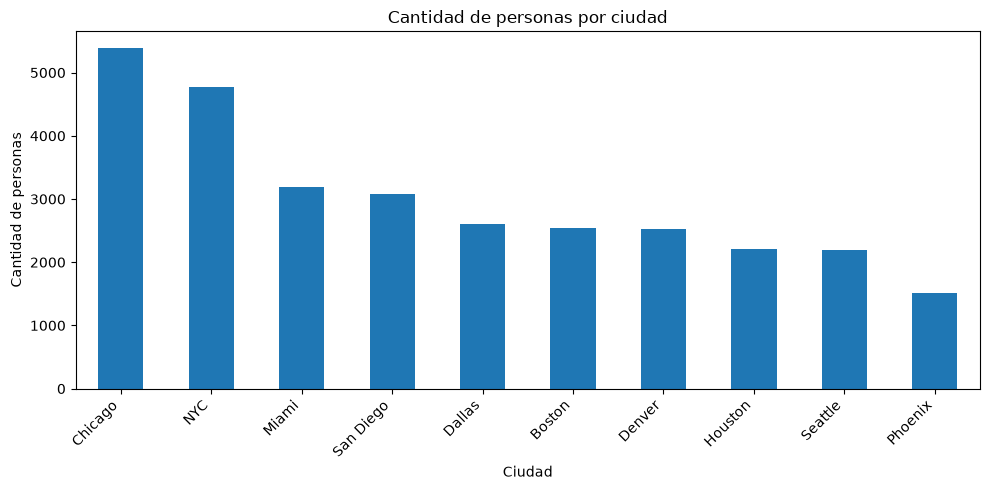

In [56]:
#Grafico de barras de cantidad de personas por ciudad

personas_por_ciudad = df_restaurantes_limpio['ciudad_residencia'].value_counts()

personas_por_ciudad.plot(kind='bar', figsize=(10, 5))

plt.title('Cantidad de personas por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Cantidad de personas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


In [57]:
distribucion_estratos = df_restaurantes_limpio['estrato_socioeconomico'].value_counts()

# Calculo el porcentaje que representa cada estrato.
porcentajes = df_restaurantes_limpio['estrato_socioeconomico'].value_counts(normalize=True) * 100

listado_estratos = pd.DataFrame({
    'Cantidad de personas': distribucion_estratos,
    'Porcentaje (%)': porcentajes
}).sort_index()

display(listado_estratos.round(2))

,Cantidad de personas,Porcentaje (%)
estrato_socioeconomico,,
Alto,9038,30.13
Bajo,6161,20.54
Medio,9325,31.08
Muy Alto,5476,18.25


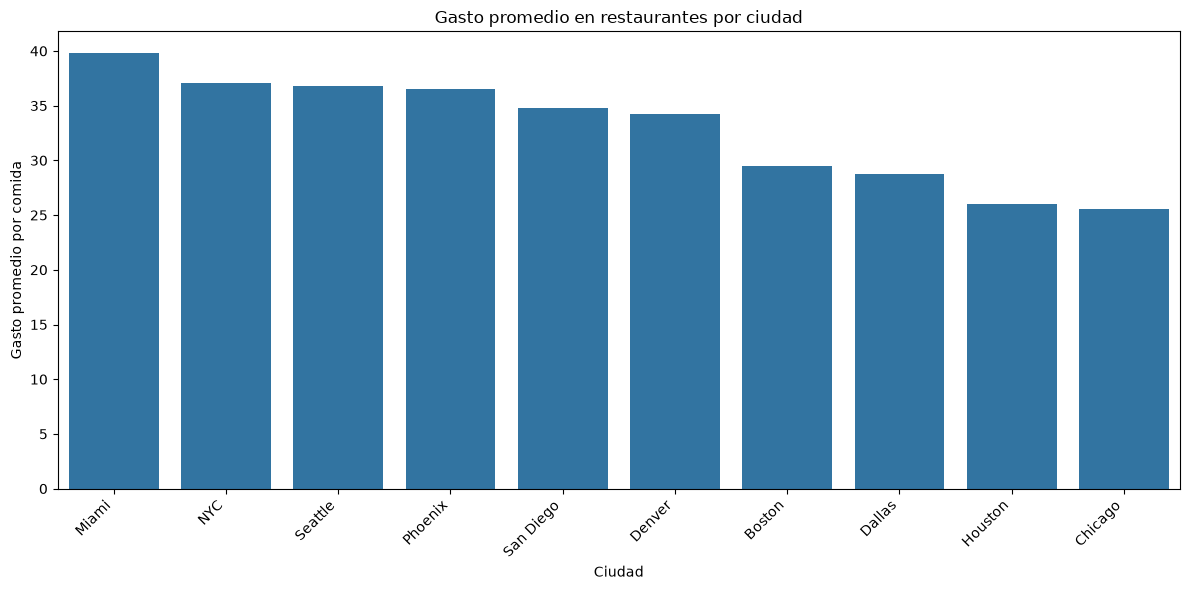

In [58]:
# Calculo el gasto promedio por ciudad.
gasto_por_ciudad = (
    df_restaurantes_limpio
    .groupby('ciudad_residencia')['promedio_gasto_comida']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=gasto_por_ciudad,
    x='ciudad_residencia',
    y='promedio_gasto_comida'
)

plt.title('Gasto promedio en restaurantes por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Gasto promedio por comida')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

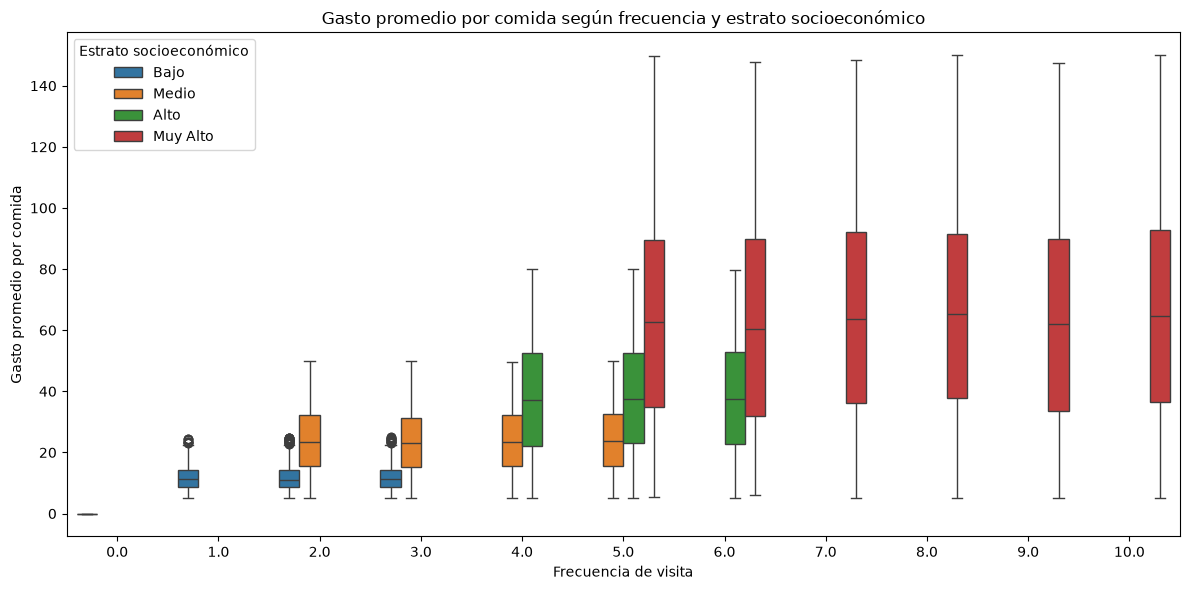

In [59]:
# Creo un gráfico de cajas para comparar los gastos entre grupos.
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_restaurantes_limpio,
    x='frecuencia_visita',
    y='promedio_gasto_comida',
    hue='estrato_socioeconomico'
)

plt.title('Gasto promedio por comida según frecuencia y estrato socioeconómico')
plt.xlabel('Frecuencia de visita')
plt.ylabel('Gasto promedio por comida')
plt.legend(title='Estrato socioeconómico')
plt.tight_layout()

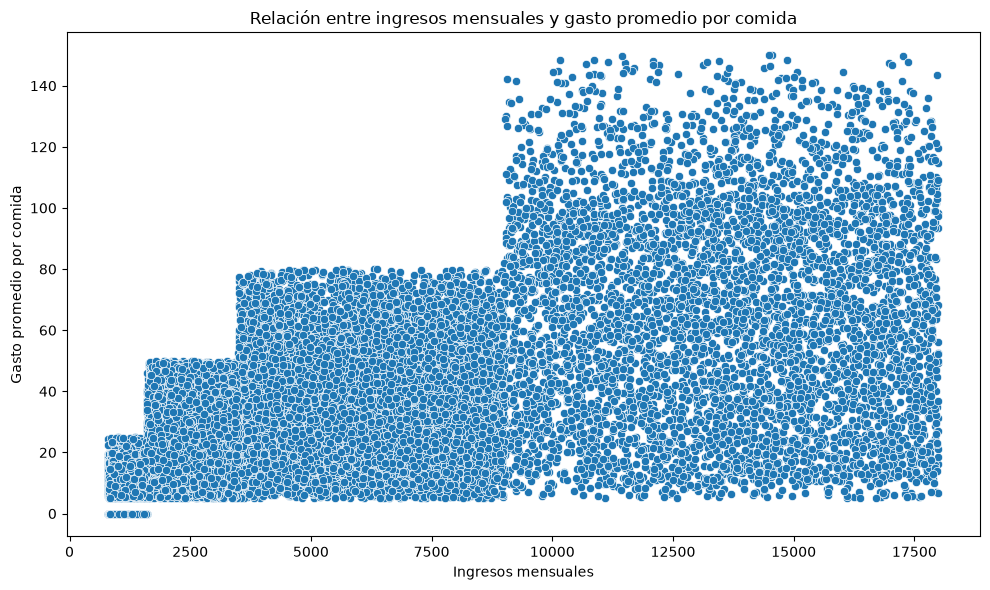

In [60]:
# Creo el gráfico de dispersión con todas las personas.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_restaurantes_limpio,
    x='ingresos_mensuales',
    y='promedio_gasto_comida'
)

plt.title('Relación entre ingresos mensuales y gasto promedio por comida')
plt.xlabel('Ingresos mensuales')
plt.ylabel('Gasto promedio por comida')
plt.tight_layout()

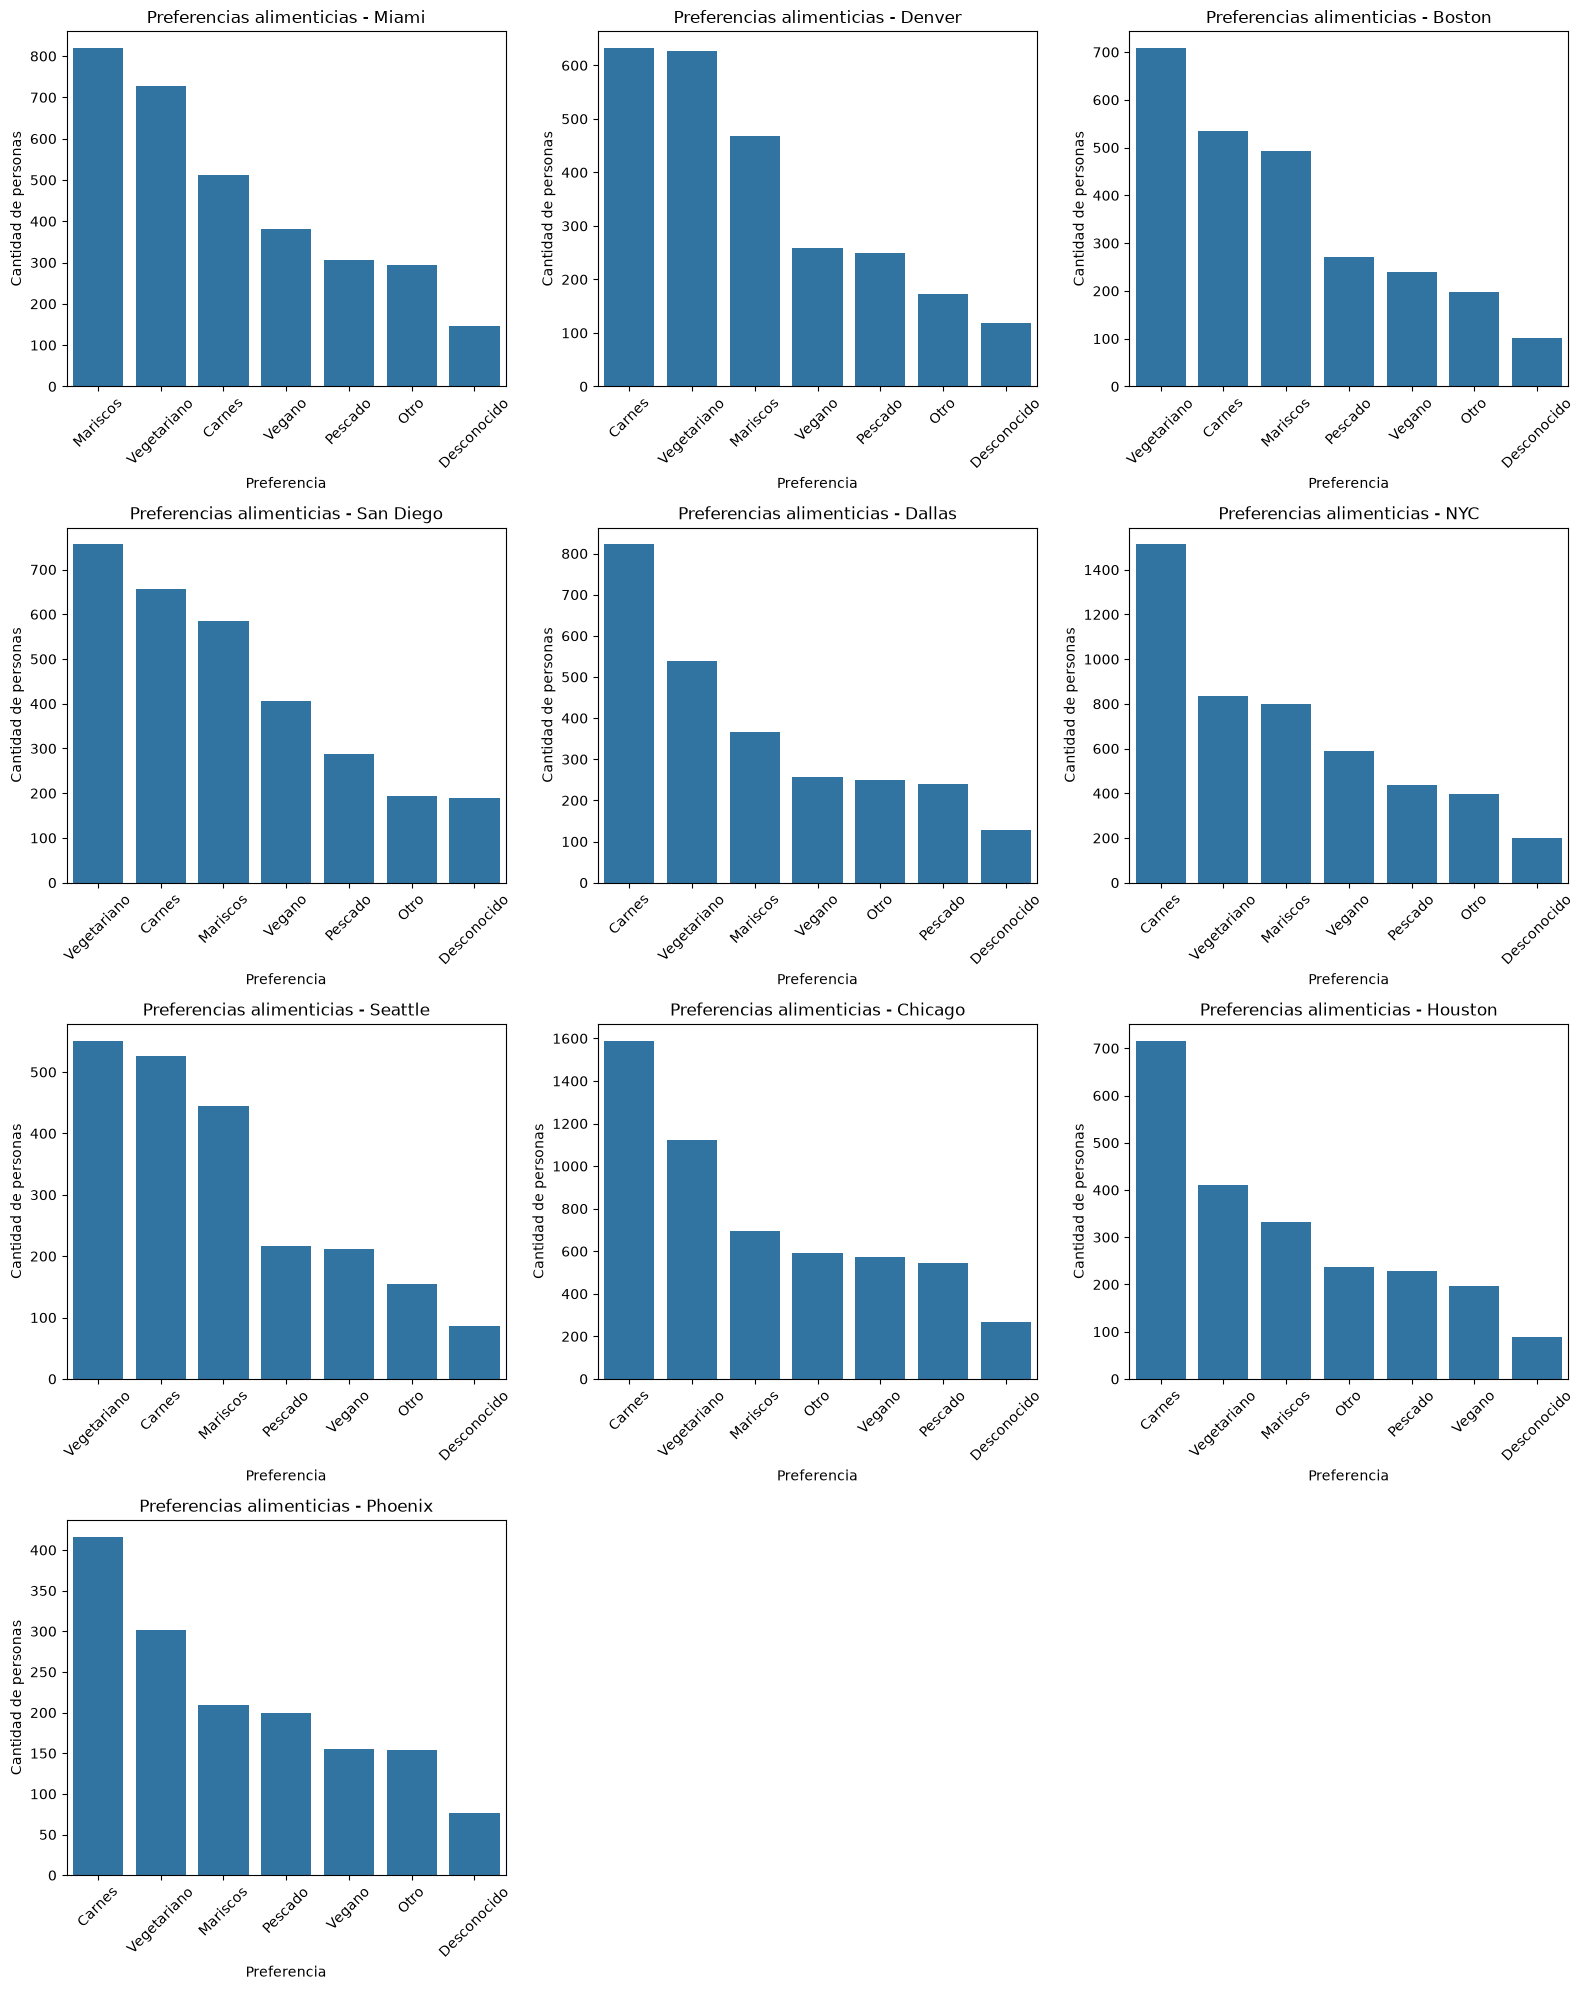

In [61]:
# Obtengo todas las ciudades presentes en el DataFrame.
ciudades = df_restaurantes_limpio['ciudad_residencia'].dropna().unique()

columnas = 3
filas = (len(ciudades) + columnas - 1) // columnas

fig, axes = plt.subplots(filas, columnas, figsize=(16, filas * 5))

axes = axes.flatten()

# Creo un gráfico de barras para cada ciudad.
for i, ciudad in enumerate(ciudades):
    datos_ciudad = df_restaurantes_limpio[
        df_restaurantes_limpio['ciudad_residencia'] == ciudad
    ]

    # Cuento las preferencias alimenticias de esa ciudad.
    preferencias = datos_ciudad['preferencias_alimenticias'].value_counts()

    sns.barplot(
        x=preferencias.index,
        y=preferencias.values,
        ax=axes[i]
    )

    axes[i].set_title(f'Preferencias alimenticias - {ciudad}')
    axes[i].set_xlabel('Preferencia')
    axes[i].set_ylabel('Cantidad de personas')
    axes[i].tick_params(axis='x', rotation=45)

# Elimino los subgráficos vacíos si la cuadrícula no está completa.
for j in range(len(ciudades), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

,preferencias_alimenticias,porcentaje,gasto_promedio
0,Carnes,25.33,75.68
1,Vegetariano,23.33,74.91
2,Mariscos,17.71,75.56
3,Vegano,10.98,76.66
4,Pescado,9.88,74.91
5,Otro,7.93,75.33
6,Desconocido,4.83,75.42


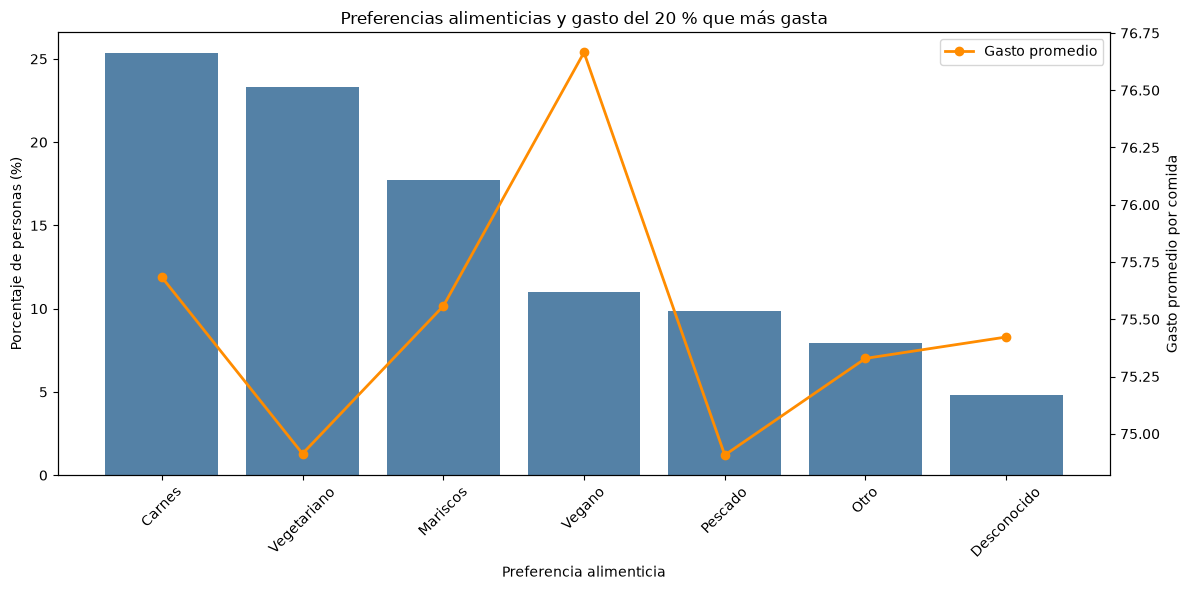

In [62]:
# Selecciono el 20 % de las personas con mayor gasto por comida.
umbral = df_restaurantes_limpio['promedio_gasto_comida'].quantile(0.80)

top_20 = df_restaurantes_limpio[
    df_restaurantes_limpio['promedio_gasto_comida'] >= umbral
].copy()

# Calculo la cantidad de personas y el gasto promedio por preferencia.
resumen = top_20.groupby('preferencias_alimenticias').agg(
    cantidad=('preferencias_alimenticias', 'count'),
    gasto_promedio=('promedio_gasto_comida', 'mean')
)

# Calculo el porcentaje de cada preferencia dentro del grupo.
resumen['porcentaje'] = resumen['cantidad'] / len(top_20) * 100

# Ordeno las preferencias de mayor a menor porcentaje.
resumen = resumen.sort_values('porcentaje', ascending=False).reset_index()

# Creo un gráfico combinado con dos ejes verticales.
fig, ax1 = plt.subplots(figsize=(12, 6))

# Las barras representan el porcentaje de personas.
sns.barplot(
    data=resumen,
    x='preferencias_alimenticias',
    y='porcentaje',
    ax=ax1,
    color='steelblue'
)
ax1.set_xlabel('Preferencia alimenticia')
ax1.set_ylabel('Porcentaje de personas (%)')
ax1.tick_params(axis='x', rotation=45)

# La línea representa el gasto promedio por comida.
ax2 = ax1.twinx()
ax2.plot(
    range(len(resumen)),
    resumen['gasto_promedio'],
    color='darkorange',
    marker='o',
    linewidth=2,
    label='Gasto promedio'
)
ax2.set_ylabel('Gasto promedio por comida')

plt.title('Preferencias alimenticias y gasto del 20 % que más gasta')
ax2.legend(loc='upper right')

plt.tight_layout()

display(resumen[['preferencias_alimenticias', 'porcentaje', 'gasto_promedio']].round(2))

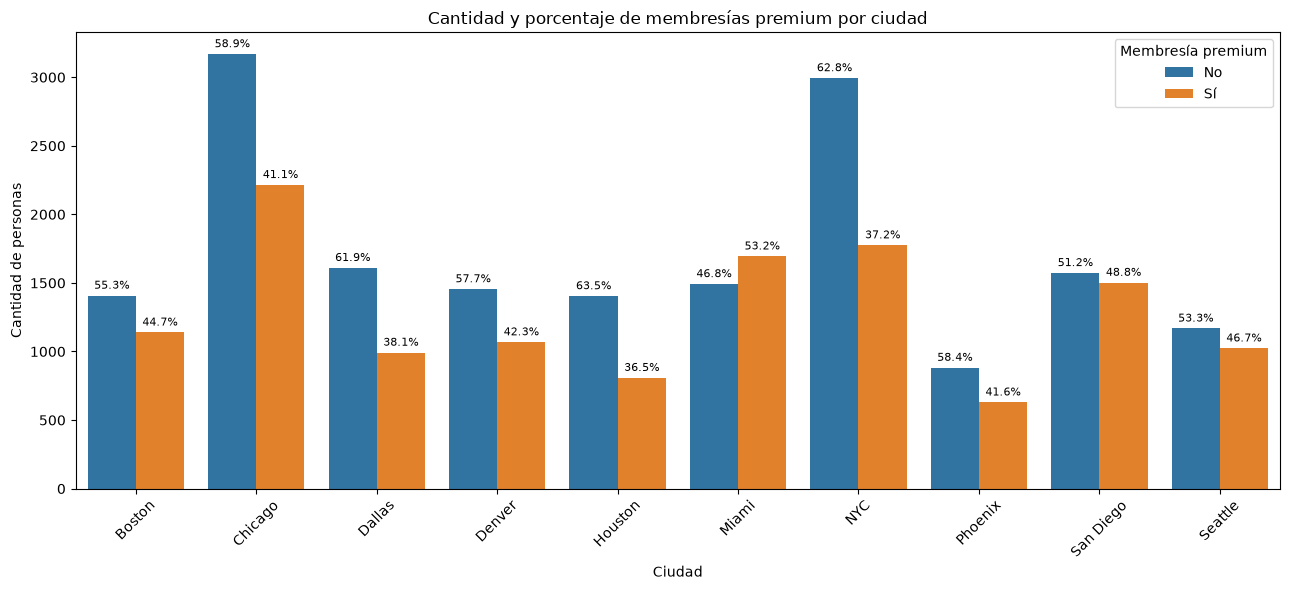

In [63]:
# Agrupo las personas por ciudad y estado de membresía.
membresias_ciudad = (
    df_restaurantes_limpio
    .groupby(['ciudad_residencia', 'membresia_premium'])
    .size()
    .reset_index(name='cantidad')
)

# Calculo el total de personas de cada ciudad.
membresias_ciudad['total_ciudad'] = (
    membresias_ciudad.groupby('ciudad_residencia')['cantidad']
    .transform('sum')
)

# Calculo el porcentaje que representa cada estado de membresía en su ciudad.
membresias_ciudad['porcentaje'] = (
    membresias_ciudad['cantidad'] /
    membresias_ciudad['total_ciudad'] * 100
)

# Creo el gráfico de barras agrupadas.
fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=membresias_ciudad,
    x='ciudad_residencia',
    y='cantidad',
    hue='membresia_premium',
    ax=ax
)

# Escribo el porcentaje encima de cada barra.
for contenedor, (_, grupo) in zip(ax.containers, 
                                  membresias_ciudad.groupby('membresia_premium', sort=False)):
    etiquetas = [
        f'{p:.1f}%' if h > 0 else ''
        for p, h in zip(grupo['porcentaje'], grupo['cantidad'])
    ]
    ax.bar_label(contenedor, labels=etiquetas, padding=3, fontsize=8)

ax.set_title('Cantidad y porcentaje de membresías premium por ciudad')
ax.set_xlabel('Ciudad')
ax.set_ylabel('Cantidad de personas')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Membresía premium')

plt.tight_layout()

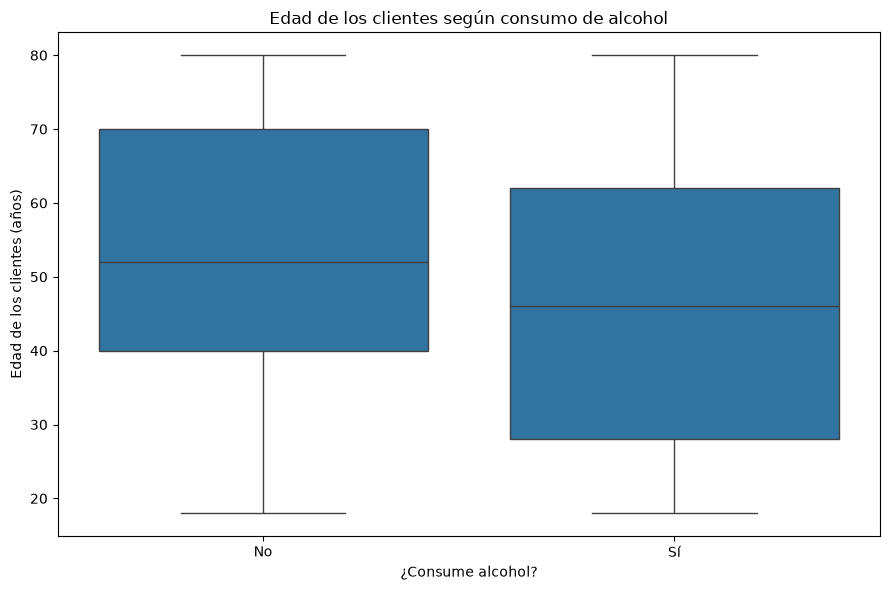

In [64]:
# Creo el gráfico para comparar las edades según el consumo de alcohol.
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_restaurantes_limpio,
    x='consume_licor',
    y='edad'
)

plt.title('Edad de los clientes según consumo de alcohol')
plt.xlabel('¿Consume alcohol?')
plt.ylabel('Edad de los clientes (años)')
plt.tight_layout()